<a href="https://colab.research.google.com/github/Insight-Sogang-Univ/insight-16th/blob/heeyeon/advanced/heeyeon/session01/%ED%8D%BC%EC%85%89%ED%8A%B8%EB%A1%A0%EC%82%AC%EC%A0%84%EA%B3%BC%EC%A0%9C_%EA%B9%80%ED%9D%AC%EC%97%B0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**1. 단층 퍼셉트론**
인공신경망의 시작이 퍼셉트론임.
- 서로 연결되어 정보를 처리 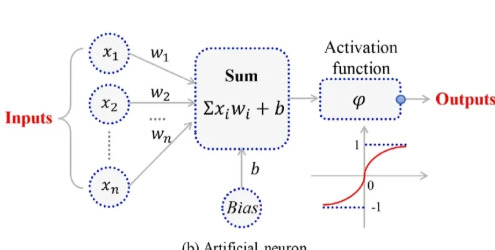


입력을 받아 가중치와 편향을 적용함. 종합 값을 임계값을 기준삼는 활성화 함수에 넘김. 기준을 통과할 경우 유의미한 값으로 남음.

즉, 기준을 넘지 않으면 0을 출력하는 가장 기본적인 인공 신경망 모델.
- 가중치는 각 입력의 중요도를 나타내며
- 편향은 출력 기준선을 조정하는 값.

입력, 가중치 반영 가중합, 활성 함수, 출력의흐름

출력은 계단 함수,
내부 계산식은 선형 회귀와 동일한 형태.
학습training은 예측이 틀릴 때마다 가중치를 정답 방향으로 조금씩 수정, 그것을 수차례 반복하며 원하는 출력값으로 점차 수정

---

**2. 단층 퍼셉트론의 한계**
그러나 한계가 있다.
단층 퍼셉트론은 단순히 입력/출력으로만 나누어져있다.
논리 게이트란? and, nand, or
n개의 입ㄹ혁과 하나의 출력값
| 게이트 | 조건 | 가중치·편향 예시 [w1, w2, b] |
| --- | --- | --- |
| **AND** | 둘 다 1일 때만 1 | `[0.5, 0.5, -0.7]` |
| **OR** | 둘 다 0일 때만 0 | `[0.6, 0.6, -0.5]` |
| **NAND** | 둘 다 1일 때만 0 | `[-0.5, -0.5, 0.7]` |
| **XOR** | 서로 다를 때만 1 | 가능한 조합이 없음 |

입력 공간을 하나의 직선(선형 경계)으로만 나눌 수 있으므로 선형 분리가 가능한 문제만 해결할 수 있음.

그런데 단층 퍼셉트론은 XOR 문제는 직선 하나로 분리할 수 없어, 학습이 불가능함. 즉 직선이 아닌 곡선과 비선형으로 분리하여야만 구현 가능!

---

**3. 다층 퍼셉트론**
그래서 나오게 된 것이 다층(비선형 구분 문제를 해결하기 위해)  
-> 구현 가능한 이유: 은닉층에서 비선형 활성화 함수를 적용해 새로운 특징을 만들고, 다음 층에서 그 특징들을 조합하기 때문  


다층 퍼셉트론은 입력층과 출력층 사이에 하나 이상의 은닉층을 두어  
퍼셉트론을 여러 층으로 쌓은 구조.  

결합한 복잡한 비선형 경계를 표현할 수 있으며,  
층 사이에 비선형 활성화 함수가 꼭 있어야함.   없으면 여러 층을 쌓아도 하나의 선형 변환과 같아지므로 비선형 활성화 함수가 반드시 필요함.   
-> 결론: 은닉층이 깊게 여러 개 쌓인 신경망을 학습시키는 것이 딥러닝   

---

**4. 딥러닝 모델의 학습 방법**
1. 순전파와 역전파
  순전파로 예측값을 계산하고,
  역전파로 각 가중치의 기울기를 구하고,
2. 손실함수
  손실 함수로 오차를 측정하고,
3. 활성화함수
  옵티마이저로 가중치를 갱신하는 과정을 반복하여 학습함

기본 원리는 경사하강법  
 경사하강법이란: 손실을 가장 작게 만드는 지점을 찾기 위해, 기울기 반대 방향으로 가중치를 조금씩 이동시킴.
 (이동 폭=학습률, 너무 크면 최적점을 지나쳐 발산하거나 너무 작으면 학습이 매우 느려짐.)

 전체 데이터를 한 번 모두 학습하는 단위를 에포크,
 한 번에 계산하는 데이터 묶음을 배치,
 배치 하나로 가중치를 한 번 갱신하는 것을 반복iteration이라 함!

 ---

**5. 순전파와 역전파, 연쇄 법칙**
-> 연쇄법칙을 통해 일어난다.  
다음층에 미틴 영향을 순서대로 곱해나가며 구하는 미분의 곱이 연쇄법칙  

자세한 의미: 순전파는 입력에서 출력 방향으로 가중합과 활성화 함수를 차례로 계산하여 예측값과 손실을 구하는 과정임.  
  역전파=출력에서 입력 방향으로 거슬러 올라가며 각 가중치가 손실에 미친 영향, 즉 기울기를 계산하는 과정임.  
  연쇄법칙=뒤쪽 층에서 계산한 기울기를 앞쪽 층 계산에 재사용

  손실 함수 = 예측값과 실제값의 차이를 수치로 표현

---

**6. 손실 함수의 정의와 종류**
손실 함수는 데이터 학습의 목표는 차이값을 최소화하는 것임. ⇒ 실제값(정답)과 예측값(출력값)의 차이를 계산하는 데 사용되는 함수

 오차의 제곱 평균인 MSE와 오차의 절댓값 평균인 MAE를 주로 사용하며,

 MSE는 큰 오차에 더 큰 벌점을
 MAE는 이상치에 덜 민감함.  

 이진 분류에는 이진 교차 엔트로피, 다중  분류에는 범주형 교차 엔트로피를 사용함.

 이를 요약하자면, 다음과 같다!  

 1. 평균 제곱 오차 (Mean Squared Error, MSE)
 2. 이진 크로스 엔트로피
 3. 크로스 엔트로피 오차
 | **손실 함수** | **사용 상황** | **예시** |
| --- | --- | --- |
| **MSE** | 회귀 문제 | 주택 가격 예측, 온도 예측, 주식 가격 예측 |
| **BCE** | 이진 분류 문제 | 이메일 스팸 필터링(스팸/정상), 질병 진단(양성/음성) |
| **CEE** | 다중 클래스 분류 문제 | 손글씨 숫자 인식(MNIST), 이미지 분류(CIFAR-10) |

---

**7. 활성화 함수의 정의와 종류**

그러나 은닉층이 굉장히 많고 각 단계마다 미분값이 1보다 작다면 한없이 영이 가까워지는 문제가 발생한다.
앞쪽 층 가줓이가 업데이트 되지 않아 학습이 제대로 이뤄지지 않는다.

활성화 함수는 비선형성이 필요하고, 미분이 되어야하고, 단층 다층마다 다르게 적용되기에 필요하다

즉 가장 기본 정의는 뉴런의 가중합 결과를 다음 층으로 전달할 출력값으로 변환하는 함수이며, 신경망에 비선형성을 부여하는 역할을 함.

-> 계단 함수(입력값과 가중치의 곱을 모두 더한 뒤, 그 합이 임계값을 넘으면 1, 아니면 0을 출력하는 함수)는 기울기가 0이어서 역전파 학습에 사용할 수 없음.

시그모이드(출력을 0과 1 사이로 변환하여 이진 분류 출력층), 기울기가 작아 층이 깊어지면 기울기 소실 문제가 발생함   
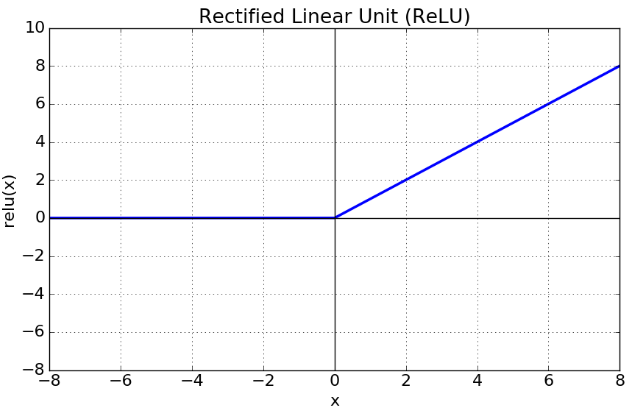
-> 주로 쓰이는 것은 ReLU 함수!  
입력이 0보다 크면 그대로, 0 이하면 0을 출력하는 비선형 함수이다.
간단하고 효율적이며 비선형성을 제공한다. 기울기 소실 문제도 반영한다 (어떻게?: 음수 구간에 작은 기울기를 주어서)  

소프트맥스는 여러 출력값을 합이 1인 확률로 변환하여 다중 분류 출력층에 사용됨. 클래스 속할 확률을 숫자로 접 사람이 확인할 수가 잇음  


순전파 = 예측
손실 계산 = 얼마나 틀렸는지 측정
역전파 = 책임 추적
가중치 업데이트 = 수정

---

**8. 옵티마이저의 정의와 종류**  

경사하강법만으로는 딥러닝의 손실함수를 예측하는 데 어려움이 있었다. 작은 웅덩이에서 갇혀버리는 문제를 해결하기 위해 몹티마이저가 등장하게되었다

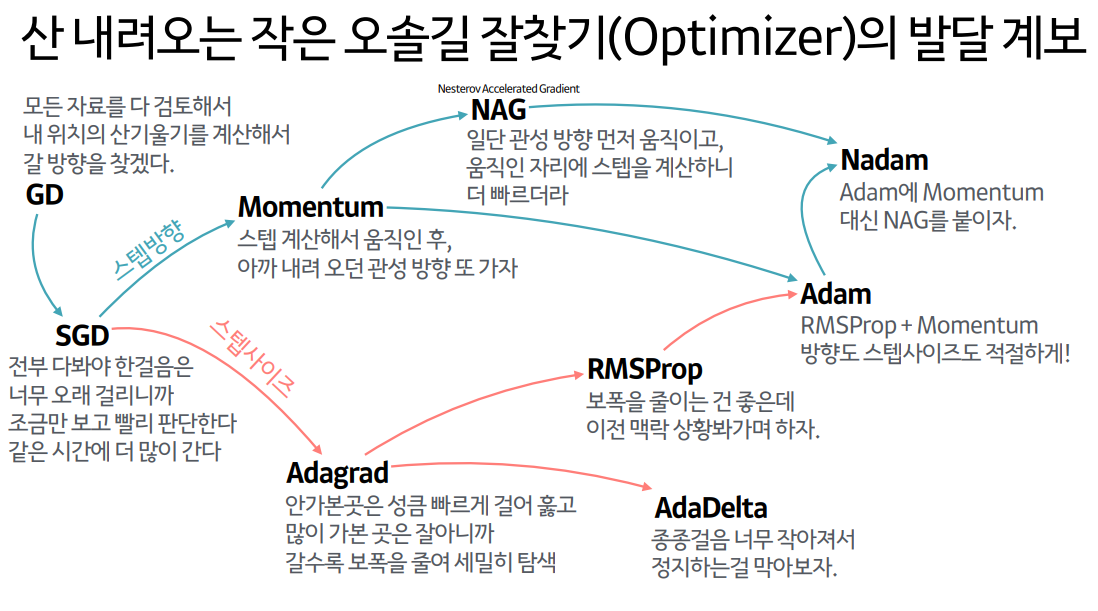

1. 모멘텀은 이전 갱신 방향의 관성을 반영하여 진동을 줄이고 수렴 속도를 높임.   

2. RMSProp은 최근 기울기 정보 위주로 학습률을 조정하여 안정적이고 빠르게 학습함. 완만한 경사에선 속도를 증가하는식으로 다르게 움직임

3. Adam은 모멘텀과 RMSProp을 결합한 방식으로, 성능이 안정적이어서 가장 널리 사용되는 기본 옵티마이저임.방향과 학습률 모두를 잡기 위한 방법

| 이럴 때 | 이걸 쓰세요 | 왜 |
| --- | --- | --- |
| **잘 모르겠다 / 대부분의 경우** | **Adam** | 방향과 보폭을 둘 다 잡음. 사실상 기본값 |
| 학습이 자꾸 한쪽으로 튄다 | 모멘텀 | 방향을 안정화 |
| 파라미터마다 기울기 크기 차이가 크다 | RMSProp | 방향별로 학습률을 따로 조정 |

#### 일단 아담으로 시작한 후 잘 안되면 바꾸자